In [1]:
import pandas as pd
import numpy as np
from sklearn.feature_selection import VarianceThreshold

In [2]:
df = pd.read_csv('rdkit_combined_df.csv')

In [3]:
df.columns

Index(['Unnamed: 0', 'MaxAbsEStateIndex', 'MaxEStateIndex',
       'MinAbsEStateIndex', 'MinEStateIndex', 'qed', 'SPS', 'MolWt',
       'HeavyAtomMolWt', 'ExactMolWt',
       ...
       'fr_sulfide', 'fr_sulfonamd', 'fr_sulfone', 'fr_term_acetylene',
       'fr_tetrazole', 'fr_thiazole', 'fr_thiocyan', 'fr_thiophene',
       'fr_unbrch_alkane', 'fr_urea'],
      dtype='object', length=211)

In [4]:
columns_to_drop = df.columns[:1].tolist()
X = df.drop(columns = columns_to_drop, axis=1)

In [5]:
X.shape

(1481, 210)

In [6]:
target_df = pd.read_csv('Combined_df.csv')

In [7]:
target_df.columns

Index(['Unnamed: 0', 'SMILES', 'PCE'], dtype='object')

In [8]:
y = target_df['PCE']

In [9]:
y.shape

(1481,)

In [10]:
X.fillna(0, inplace = True)
X=X.select_dtypes(include='number')
X = X.astype(np.float32)
max_value = np.finfo(np.float32).max
X = X.loc[:, (X.iloc[:,:] <= max_value).all(axis=0)]

/home/hamza/anaconda3/envs/active_learning/lib/python3.12/site-packages/pandas/core/dtypes/astype.py:133: RuntimeWarning: overflow encountered in cast
  return arr.astype(dtype, copy=True)


In [11]:
X.shape

(1481, 205)

In [12]:
def remove_low_variance(input_data, threshold=0.1):
    selection = VarianceThreshold(threshold)
    selection.fit(input_data)
    return input_data[input_data.columns[selection.get_support(indices=True)]]

In [13]:
X = remove_low_variance(X, threshold=0.1)
X

,MaxAbsEStateIndex,MaxEStateIndex,MinAbsEStateIndex,MinEStateIndex,SPS,MolWt,HeavyAtomMolWt,ExactMolWt,NumValenceElectrons,AvgIpc,...,fr_imide,fr_ketone,fr_ketone_Topliss,fr_methoxy,fr_nitrile,fr_piperdine,fr_pyridine,fr_sulfide,fr_thiazole,fr_thiophene
0,19.160440,19.160440,0.848696,-7.496612,36.548672,3170.614014,2938.773926,3167.584717,1182.0,1.475750,...,0.0,0.0,0.0,0.0,8.0,0.0,0.0,0.0,0.0,8.0
1,16.387346,16.387346,1.151380,-6.600159,33.325001,1103.494019,1030.917969,1102.484009,410.0,1.441446,...,0.0,2.0,2.0,2.0,0.0,0.0,0.0,0.0,0.0,2.0
2,16.532236,16.532236,0.526607,-5.374990,29.381819,1524.046021,1437.358032,1522.544678,550.0,1.450126,...,0.0,2.0,2.0,0.0,0.0,0.0,0.0,0.0,0.0,4.0
3,16.556942,16.556942,0.537908,-5.389678,29.000000,1556.043945,1469.355957,1554.534546,562.0,1.486817,...,0.0,2.0,2.0,2.0,0.0,0.0,0.0,0.0,0.0,4.0
4,10.857450,10.857450,0.565676,-6.364455,34.557377,883.375000,820.879028,882.385742,318.0,1.523381,...,0.0,0.0,0.0,0.0,4.0,0.0,0.0,0.0,0.0,4.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1476,16.281013,16.281013,0.672245,-7.047593,35.137615,1630.006958,1527.191040,1626.548340,572.0,1.476827,...,0.0,2.0,2.0,0.0,3.0,0.0,0.0,0.0,0.0,4.0
1477,15.752806,15.752806,0.631875,-5.663429,32.343750,1772.536011,1649.560059,1770.869629,658.0,1.459325,...,0.0,0.0,0.0,0.0,3.0,0.0,0.0,0.0,2.0,2.0
1478,15.117061,15.117061,0.143028,-5.309186,28.714285,1582.208008,1493.504028,1580.541626,562.0,1.460568,...,0.0,0.0,0.0,0.0,3.0,0.0,0.0,0.0,2.0,2.0
1479,15.893785,15.893785,1.172863,-6.997897,38.446602,1501.337036,1383.401001,1499.743042,554.0,1.503114,...,2.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,6.0


In [14]:
X.shape

(1481, 126)

In [15]:
X.columns

Index(['MaxAbsEStateIndex', 'MaxEStateIndex', 'MinAbsEStateIndex',
       'MinEStateIndex', 'SPS', 'MolWt', 'HeavyAtomMolWt', 'ExactMolWt',
       'NumValenceElectrons', 'AvgIpc',
       ...
       'fr_imide', 'fr_ketone', 'fr_ketone_Topliss', 'fr_methoxy',
       'fr_nitrile', 'fr_piperdine', 'fr_pyridine', 'fr_sulfide',
       'fr_thiazole', 'fr_thiophene'],
      dtype='object', length=126)

In [16]:
def correlation(dataset, threshold):
    col_corr = set()  # Set of all the names of correlated columns
    corr_matrix = dataset.corr()
    for i in range(len(corr_matrix.columns)):
        for j in range(i):
            if (corr_matrix.iloc[i, j]) > threshold: # we are interested in absolute coeff value
                colname = corr_matrix.columns[i]  # getting the name of column
                col_corr.add(colname)
    return col_corr
corr_features = correlation(X, 0.8)
print('Features with correlation more than 0.8 :',len(set(corr_features)))
X = X.drop(list(corr_features & set(X.columns)), axis=1)

Features with correlation more than 0.8 : 61


In [17]:
X.shape

(1481, 65)

In [18]:
from sklearn.preprocessing import KernelCenterer
from sklearn.metrics.pairwise import pairwise_kernels

In [19]:
K = pairwise_kernels(X, metric='linear')
K

array([[10666605.  ,  3687182.  ,  5115103.5 , ...,  5303754.  ,
         5030424.  ,   849587.  ],
       [ 3687182.  ,  1285775.1 ,  1782266.6 , ...,  1842530.5 ,
         1742742.9 ,   294896.8 ],
       [ 5115103.5 ,  1782266.6 ,  2494617.  , ...,  2573831.  ,
         2415148.2 ,   416825.94],
       ...,
       [ 5303754.  ,  1842530.5 ,  2573831.  , ...,  2671872.2 ,
         2504892.2 ,   436018.66],
       [ 5030424.  ,  1742742.9 ,  2415148.2 , ...,  2504892.2 ,
         2394132.5 ,   402287.12],
       [  849587.  ,   294896.8 ,   416825.94, ...,   436018.66,
          402287.12,    81327.09]], dtype=float32)

In [20]:
X_new = KernelCenterer().fit_transform(K, y)

In [21]:
X_new.shape

(1481, 1481)

In [22]:
y.shape

(1481,)

In [23]:
from sklearn.model_selection import KFold
from sklearn.model_selection import train_test_split
train_inputs, test_inputs, train_outputs, test_outputs = train_test_split(X_new,y,test_size=0.1,random_state=1)

In [24]:
train_inputs.shape, test_inputs.shape

((1332, 1481), (149, 1481))

In [25]:
train_outputs.shape, test_outputs.shape

((1332,), (149,))

In [26]:
import numpy as np
from sklearn.gaussian_process import GaussianProcessRegressor
from sklearn.gaussian_process.kernels import RBF, Matern, ConstantKernel as C

In [27]:
# Define the kernel
# C(1.0) is a constant kernel, multiplying Matérn and RBF kernels
kernel = C(1.0, (1e-4, 1e1)) * (Matern(length_scale=1.0, length_scale_bounds=(1e-4, 1e1), nu=1.5) + RBF(length_scale=1.0, length_scale_bounds=(1e-4, 1e1)))

In [28]:
# Now, kernel is a combination of Matern and RBF

# Step 3: Instantiate the GaussianProcessRegressor
gpr = GaussianProcessRegressor(kernel=kernel, n_restarts_optimizer=10)

In [29]:
# Step 4: Fit the model
gpr.fit(train_inputs, train_outputs)

/home/hamza/anaconda3/envs/active_learning/lib/python3.12/site-packages/sklearn/gaussian_process/_gpr.py:659: ConvergenceWarning: lbfgs failed to converge (status=2):
ABNORMAL_TERMINATION_IN_LNSRCH.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
  _check_optimize_result("lbfgs", opt_res)
/home/hamza/anaconda3/envs/active_learning/lib/python3.12/site-packages/sklearn/gaussian_process/kernels.py:452: ConvergenceWarning: The optimal value found for dimension 0 of parameter k2__k2__length_scale is close to the specified upper bound 10.0. Increasing the bound and calling fit again may find a better value.
  warnings.warn(


GaussianProcessRegressor(kernel=1**2 * Matern(length_scale=1, nu=1.5) + RBF(length_scale=1),
                         n_restarts_optimizer=10)

In [30]:
test_pred, test_std = gpr.predict(test_inputs, return_std=True)

In [32]:
for i, (mean, std) in enumerate(zip(test_pred, test_std)):
    print(f"Test point {test_inputs[i][0]}: Predicted mean = {mean:.3f}, Predicted std = {std:.3f}")

Test point -548884.75: Predicted mean = 0.000, Predicted std = 3.579
Test point 135309.0: Predicted mean = 2.980, Predicted std = 0.000
Test point 106837.75: Predicted mean = 0.000, Predicted std = 3.579
Test point -193471.5: Predicted mean = 8.880, Predicted std = 0.000
Test point -1209240.0: Predicted mean = 0.000, Predicted std = 3.579
Test point 241695.25: Predicted mean = 0.000, Predicted std = 3.579
Test point -1126641.5: Predicted mean = 0.000, Predicted std = 3.579
Test point 1404580.75: Predicted mean = 0.000, Predicted std = 3.579
Test point 351296.0: Predicted mean = 0.000, Predicted std = 3.579
Test point -245769.25: Predicted mean = 0.000, Predicted std = 3.579
Test point -184906.25: Predicted mean = 0.000, Predicted std = 3.579
Test point -320719.0: Predicted mean = 0.000, Predicted std = 3.579
Test point 7678.0: Predicted mean = 0.000, Predicted std = 3.579
Test point 125180.25: Predicted mean = 0.000, Predicted std = 3.579
Test point -278526.75: Predicted mean = 0.000, 

In [33]:
import matplotlib.pyplot as plt

ValueError: x and y must be the same size

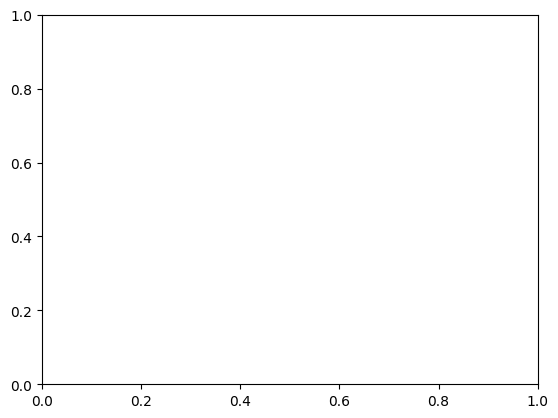

In [34]:
# Visualize the training data
plt.scatter(train_inputs, train_outputs, color='black', label='Training data')

In [ ]:


# Plot the mean predictions with the shaded uncertainty region
X_range = np.linspace(0, 10, 100).reshape(-1, 1)
y_mean, y_std = gpr.predict(X_range, return_std=True)

plt.plot(X_range, y_mean, label='Predicted mean')
plt.fill_between(X_range.ravel(), y_mean - y_std, y_mean + y_std, alpha=0.3, color='gray', label='Uncertainty')

plt.xlabel('X')
plt.ylabel('Y')
plt.legend()
plt.show()